# EuroSAT — PHASE 2: Band Selection Comparison

This notebook is the companion to `eurosat_model_comparison.ipynb`. Phase 1 fixed the input to plain RGB and compared four pretrained backbones (ConvNeXtTiny, ResNet50, EfficientNetB0, MobileNetV2). Phase 2 uses ConvNeXtTiny model and tests which bands gives the best accuracy and better results.

Three experiments are run with an identical model, training setup, and data split:

| Experiment | Bands used | # Channels |
|---|---|---|
| A — RGB | Red, Green, Blue | 3 |
| B — RGB + NIR | Red, Green, Blue, Near-Infrared | 4 |
| C — Multispectral | All 13 Sentinel-2 bands | 13 |

## 1. Objective

RGB-only classification throws away most of what Sentinel-2 actually captures — 10 of its 13 bands never make it into a JPEG. This notebook measures whether that discarded spectral information is actually worth having for EuroSAT land-cover classification.

The architecture, training regimen (frozen backbone, same head, same callbacks, same epoch budget) and evaluation metrics are all kept identical to Phase 1 — only the band selection changes between experiments — so any difference in the results can be attributed to the input bands rather than to something else changing at the same time.

## 2. Multispectral EuroSAT Dataset

Same source as Phase 1's `apollo2506/eurosat-dataset` Kaggle dataset — it ships **both** releases side by side in one archive:

- `EuroSAT/` — the RGB JPEGs Phase 1 used
- `EuroSATallBands/` — the multispectral release this notebook needs: one 13-band GeoTIFF per sample, plus its own `train.csv` / `validation.csv` / `test.csv` and a `label_map.json`

Because both releases ship together with their own official splits, the multispectral experiments below use `EuroSATallBands`'s own CSVs rather than building a fresh split — that keeps this notebook's split consistent with the dataset's intended train/val/test partition instead of an ad-hoc one.

- **Format:** GeoTIFF, one file per sample, shape `(13, H, W)`, raw Sentinel‑2 reflectance values (not yet scaled to 0–255 like the RGB version).
- **Classes:** the same 10 land-use/land-cover classes as Phase 1.

In [1]:
!pip install -q rasterio

In [2]:
import os
import glob
import json
import time
import zipfile
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    Rescaling,
    GlobalAveragePooling2D,
    Dropout,
    Dense,
)
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.callbacks import EarlyStopping

### 2.2 Download & Extract Dataset

In [3]:
!mkdir -p ~/.kaggle
!cp "kaggle (1).json" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download apollo2506/eurosat-dataset

zip_ref = zipfile.ZipFile('/content/eurosat-dataset.zip', 'r')
zip_ref.extractall('/content/')
zip_ref.close()

Dataset URL: https://www.kaggle.com/datasets/apollo2506/eurosat-dataset
License(s): CC0-1.0
100% 2.04G/2.04G [00:20<00:00, 106MB/s] 



### 2.3 Dataset Path, Classes & Label Map

In [4]:
DATASET_PATH = "/content/EuroSATallBands"

with open(os.path.join(DATASET_PATH, "label_map.json")) as f:
    label_map = json.load(f)

# label_map.json could be {name: index} or {index: name} depending on how it
# was exported -- normalize either direction into an index-ordered list so
# labels[i] always matches the integer in the CSVs' "Label" column.
if all(str(k).isdigit() for k in label_map.keys()):
    idx_to_name = {int(k): v for k, v in label_map.items()}
else:
    idx_to_name = {v: k for k, v in label_map.items()}

labels = [idx_to_name[i] for i in sorted(idx_to_name)]

print("Classes (index order):", labels)

Classes (index order): ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


### 2.4 Load Train / Validation / Test CSVs

loading data from `EuroSATallBands`.

In [5]:
train_df = pd.read_csv(os.path.join(DATASET_PATH, "train.csv"))
val_df = pd.read_csv(os.path.join(DATASET_PATH, "validation.csv"))
test_df = pd.read_csv(os.path.join(DATASET_PATH, "test.csv"))

for df in (train_df, val_df, test_df):
    if "Unnamed: 0" in df.columns:
        df.drop(columns=["Unnamed: 0"], inplace=True)

# If the runtime is RAM-constrained, lower this (e.g. 0.3) to work with a
# stratified subset instead of the full ~27,000 images. 1.0 uses everything.
SAMPLE_FRAC = 1.0

if SAMPLE_FRAC < 1.0:
    train_df = train_df.groupby("Label", group_keys=False).apply(
        lambda g: g.sample(frac=SAMPLE_FRAC, random_state=42)
    ).reset_index(drop=True)
    val_df = val_df.groupby("Label", group_keys=False).apply(
        lambda g: g.sample(frac=SAMPLE_FRAC, random_state=42)
    ).reset_index(drop=True)
    test_df = test_df.groupby("Label", group_keys=False).apply(
        lambda g: g.sample(frac=SAMPLE_FRAC, random_state=42)
    ).reset_index(drop=True)

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))
print(train_df.head())

# Basename -> full path lookup, used as a fallback when Filename doesn't
# already include the class subfolder.
_path_index = {}
for root, _, files in os.walk(DATASET_PATH):
    for fn in files:
        if fn.lower().endswith(".tif"):
            _path_index[fn] = os.path.join(root, fn)

def resolve_path(filename):
    candidate = os.path.join(DATASET_PATH, filename)
    if os.path.exists(candidate):
        return candidate
    return _path_index.get(os.path.basename(filename), candidate)

Train: 19317 | Val: 5519 | Test: 2759
                                            Filename  Label  \
0               PermanentCrop/PermanentCrop_2401.tif      6   
1               PermanentCrop/PermanentCrop_1006.tif      6   
2  HerbaceousVegetation/HerbaceousVegetation_1025...      2   
3                           SeaLake/SeaLake_1439.tif      9   
4                               River/River_1052.tif      8   

              ClassName  
0         PermanentCrop  
1         PermanentCrop  
2  HerbaceousVegetation  
3               SeaLake  
4                 River  


## 3. Band Selection

Sentinel-2 provides 13 bands at three native resolutions (all resampled to 10 m / 64×64 px in this dataset). The table below is the reference used to build each experiment's band subset.

| # | Band | Description | Native resolution |
|---|------|-------------|--------------------|
| 0 | B01 | Coastal aerosol | 60 m |
| 1 | B02 | Blue | 10 m |
| 2 | B03 | Green | 10 m |
| 3 | B04 | Red | 10 m |
| 4 | B05 | Red Edge 1 | 20 m |
| 5 | B06 | Red Edge 2 | 20 m |
| 6 | B07 | Red Edge 3 | 20 m |
| 7 | B08 | NIR | 10 m |
| 8 | B8A | Narrow NIR | 20 m |
| 9 | B09 | Water vapour | 60 m |
| 10 | B10 | SWIR – Cirrus | 60 m |
| 11 | B11 | SWIR 1 | 20 m |
| 12 | B12 | SWIR 2 | 20 m |

`BAND_SETS` below is what each of the three experiments actually pulls out of the 13-band cube — everything downstream (training, metrics, plots, table) loops over this dict, the same pattern Phase 1 used for `MODEL_CONFIGS`.

In [6]:
BAND_NAMES = ["B01", "B02", "B03", "B04", "B05", "B06", "B07",
              "B08", "B8A", "B09", "B10", "B11", "B12"]
BAND_INDEX = {name: i for i, name in enumerate(BAND_NAMES)}

BAND_SETS = {
    "RGB": [BAND_INDEX["B04"], BAND_INDEX["B03"], BAND_INDEX["B02"]],
    "RGB + NIR": [BAND_INDEX["B04"], BAND_INDEX["B03"], BAND_INDEX["B02"], BAND_INDEX["B08"]],
    "Multispectral (13 bands)": list(range(13)),
}

for exp_name, idx in BAND_SETS.items():
    print(f"{exp_name:28s} -> {len(idx)} band(s): {[BAND_NAMES[i] for i in idx]}")

RGB                          -> 3 band(s): ['B04', 'B03', 'B02']
RGB + NIR                    -> 4 band(s): ['B04', 'B03', 'B02', 'B08']
Multispectral (13 bands)     -> 13 band(s): ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12']


## 4. Data Preprocessing

### 4.1 Load the Full 13-Band Cube (once)

**Memory note:** the first version of this cell loaded every image into a Python list as `float32` and then let `np.array(...)` copy that list into a second full-size array — for ~27,000 13-band images that briefly needs well over 10 GB and is what crashed the runtime. This version instead:

- **preallocates** the output array up front (no list -> array copy, so peak memory is just the array itself), and
- stores the data as **`uint8`** (0-255), not `float32` — since the pixel values are already being rescaled into 0-255 anyway, there's no need to keep them as 4-byte floats in host RAM. The model's `Rescaling` layer (Section 5) converts back to float and normalizes on the fly per batch, on the GPU, so nothing downstream changes.

That's roughly a **7-8x** reduction in peak RAM for this step (float32 list+array vs. preallocated uint8). If it's still too much for the runtime, lower `SAMPLE_FRAC` in Section 2.4 to work with a subset first.

Rather than re-reading every `.tif` file once per experiment, all 13 bands are loaded **once** into memory per split and cached as `X_train_full` / `X_val_full` / `X_test_full`. Each experiment then just slices the bands it needs out of that cache.

Raw Sentinel-2 reflectance values aren't in a neat 0-255 range the way the RGB JPEGs were, so each band is clipped at a fixed reflectance ceiling and rescaled into 0-255. `3000` is a standard clipping point for Sentinel-2 surface reflectance, and — importantly — the **same clip value is used for every band**, so the three experiments stay comparable to each other.

In [7]:
REFLECTANCE_CLIP = 3000.0

def load_multiband(df):
    n = len(df)
    X = np.empty((n, 64, 64, 13), dtype="uint8")
    y = np.empty((n,), dtype="int32")

    for i, (_, row) in enumerate(df.iterrows()):
        path = resolve_path(row["Filename"])
        with rasterio.open(path) as src:
            img = src.read()  # (13, H, W)
        img = np.transpose(img, (1, 2, 0)).astype("float32")  # (H, W, 13)
        img = np.clip(img, 0, REFLECTANCE_CLIP) / REFLECTANCE_CLIP * 255.0
        X[i] = img.astype("uint8")
        y[i] = row["Label"]

        if i % 2000 == 0:
            print(f"  loaded {i}/{n}", end="\r")

    return X, y


X_train_full, y_train = load_multiband(train_df)
gc.collect()
X_val_full, y_val = load_multiband(val_df)
gc.collect()
X_test_full, y_test = load_multiband(test_df)
gc.collect()

print("Train:", X_train_full.shape, X_train_full.dtype, y_train.shape)
print("Val:  ", X_val_full.shape, y_val.shape)
print("Test: ", X_test_full.shape, y_test.shape)

Train: (19317, 64, 64, 13) uint8 (19317,)
Val:   (5519, 64, 64, 13) (5519,)
Test:  (2759, 64, 64, 13) (2759,)


### 4.2 Band Selection Helper & Sanity Check

`select_bands` is the one-liner every experiment calls to turn the cached 13-band cube into the 3/4/13-channel input it actually needs. As a sanity check, the RGB bands of one sample are plotted — it should look like an ordinary land-cover photo, confirming the band ordering and clipping are correct before any training happens.

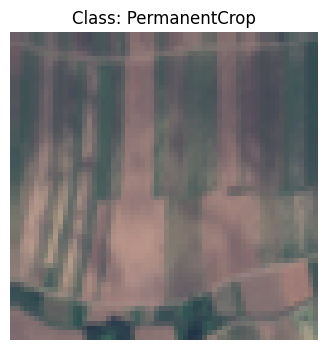

In [8]:
def select_bands(X_full, band_indices):
    return X_full[..., band_indices]


sample_rgb = select_bands(X_train_full[:1], BAND_SETS["RGB"])[0] / 255.0

plt.figure(figsize=(4, 4))
plt.imshow(np.clip(sample_rgb, 0, 1))
plt.title("Class: " + labels[y_train[0]])
plt.axis("off")
plt.show()

## 5. ConvNeXtTiny Architecture

The backbone is fixed to **ConvNeXtTiny** with frozen ImageNet weights for all three experiments — same head (`GlobalAveragePooling2D -> Dropout -> Dense(softmax)`), same optimizer, same callbacks as Phase 1.

The one real complication: ConvNeXtTiny's pretrained weights expect **3-channel** input. That's free for Experiment A (RGB is already 3 channels), but Experiments B and C need 4 and 13 channels respectively. Rather than throwing the pretrained weights away for those two runs, a small **learnable 1×1 convolution ("band adapter")** is inserted in front of the backbone whenever the channel count isn't 3. It projects however many bands are selected down to 3 channels, and unlike the frozen backbone it's left trainable, so the network can learn its own useful combination of the extra bands rather than the notebook guessing one by hand. A fixed `Rescaling` step ahead of the adapter keeps the normalization identical across all three experiments so the comparison isn't confounded by different input scaling.

### 5.1 Build / Train / Evaluate Helpers

In [9]:
NUM_CLASSES = 10
EPOCHS = 30
BATCH_SIZE = 32
INPUT_HW = (64, 64)


def build_model(num_bands, input_hw=INPUT_HW, num_classes=NUM_CLASSES):
    h, w = input_hw

    # Reset Keras''s global state before building each new backbone so layer
    # names/graph bookkeeping from the previous experiment don''t pile up.
    tf.keras.backend.clear_session()

    base_model = ConvNeXtTiny(
        weights="imagenet",
        include_top=False,
        input_shape=(h, w, 3)
    )
    base_model.trainable = False

    layers_list = [Rescaling(scale=1 / 127.5, offset=-1, input_shape=(h, w, num_bands))]

    if num_bands != 3:
        # Learnable N-band -> 3-channel projection so the pretrained
        # backbone can still be reused for the 4- and 13-channel inputs.
        layers_list.append(Conv2D(3, kernel_size=1, padding="same", name="band_adapter"))

    layers_list.append(base_model)
    layers_list += [
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation="softmax"),
    ]

    model = Sequential(layers_list)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def train_and_evaluate(exp_name, band_indices,
                        X_train_full, y_train,
                        X_val_full, y_val,
                        X_test_full, y_test,
                        labels,
                        epochs=EPOCHS,
                        batch_size=BATCH_SIZE):

    print("\n" + "=" * 60)
    print("TRAINING:", exp_name, f"({len(band_indices)} band(s))")
    print("=" * 60)

    Xtr = select_bands(X_train_full, band_indices)
    Xv = select_bands(X_val_full, band_indices)
    Xte = select_bands(X_test_full, band_indices)

    model = build_model(num_bands=len(band_indices))

    callback = EarlyStopping(
        monitor="val_loss",
        patience=5,
        verbose=1,
        min_delta=0.001,
        mode="auto",
        restore_best_weights=True
    )

    start_time = time.time()

    history = model.fit(
        Xtr, y_train,
        validation_data=(Xv, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[callback],
        verbose=1
    )

    training_time_sec = time.time() - start_time

    # Xtr/Xv are no longer needed once training has finished -- drop them
    # before evaluation/prediction so peak RAM doesn''t stack across runs.
    del Xtr, Xv
    gc.collect()

    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])

    test_loss, test_accuracy = model.evaluate(Xte, y_test, verbose=0)

    predictions = model.predict(Xte, verbose=0)
    y_pred = np.argmax(predictions, axis=1)

    macro_precision = precision_score(y_test, y_pred, average="macro")
    macro_recall = recall_score(y_test, y_pred, average="macro")
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    weighted_f1 = f1_score(y_test, y_pred, average="weighted")

    cm = confusion_matrix(y_test, y_pred)
    report_str = classification_report(y_test, y_pred, target_names=labels)

    print("\nTest Accuracy:", test_accuracy, "| Macro F1:", macro_f1)
    print("Training Time: {:.1f}s ({:.2f} min)".format(training_time_sec, training_time_sec / 60))

    return {
        "name": exp_name,
        "num_bands": len(band_indices),
        "model": model,
        "history": history,
        "test_accuracy": test_accuracy,
        "test_loss": test_loss,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "training_time_sec": training_time_sec,
        "confusion_matrix": cm,
        "classification_report": report_str,
        "y_pred": y_pred,
    }


def free_run_memory():
    """Call between experiments to release the previous model/graph."""
    gc.collect()

## 6. Experiment A — RGB

Baseline: the same 3 visible bands Phase 1 trained on, now loaded from the multispectral archive instead of the JPEG release. (Less accuracy)

In [10]:
results = {}

results["RGB"] = train_and_evaluate(
    "RGB", BAND_SETS["RGB"],
    X_train_full, y_train,
    X_val_full, y_val,
    X_test_full, y_test,
    labels
)
free_run_memory()


TRAINING: RGB (3 band(s))
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 40s 42ms/step - accuracy: 0.3089 - loss: 1.8673 - val_accuracy: 0.3937 - val_loss: 1.6272
Epoch 2/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.3928 - loss: 1.6227 - val_accuracy: 0.4416 - val_loss: 1.5197
Epoch 3/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.4145 - loss: 1.5451 - val_accuracy: 0.4486 - val_loss: 1.4942
Epoch 4/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.4367 - loss: 1.4960 - val_accuracy: 0.4196 - val_loss: 1.4607
Epoch 5/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.4411 - loss: 1.4686 - val_accuracy: 0.4707 - val_loss: 1.4054
Epoch 6/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.4468 - loss: 1.4508 - val_accuracy: 0.4849 - val_loss: 1.4037
Epoch 7/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.4501 - loss: 1.4276 - val_accuracy: 0.4385 - val_loss: 1.4031
Epoch 8/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.4531 - loss: 1.4171 - val_

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m


Test Accuracy: 0.5059804320335388 | Macro F1: 0.45752417970754866
Training Time: 354.3s (5.91 min)


## 7. Experiment B — RGB + NIR

Adds a single band — B08 (NIR) — on top of the RGB baseline. NIR is the cheapest possible upgrade: vegetation reflects it strongly while water absorbs it almost completely, so this band alone is expected to help most on the classes that are easily confused in plain RGB (e.g. `Pasture` vs `PermanentCrop`, or `River` vs `SeaLake`).

In [11]:
results["RGB + NIR"] = train_and_evaluate(
    "RGB + NIR", BAND_SETS["RGB + NIR"],
    X_train_full, y_train,
    X_val_full, y_val,
    X_test_full, y_test,
    labels
)
free_run_memory()


TRAINING: RGB + NIR (4 band(s))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 53s 61ms/step - accuracy: 0.4666 - loss: 1.5105 - val_accuracy: 0.6572 - val_loss: 0.9564
Epoch 2/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.7251 - loss: 0.8369 - val_accuracy: 0.7842 - val_loss: 0.6825
Epoch 3/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.7860 - loss: 0.6289 - val_accuracy: 0.8251 - val_loss: 0.5321
Epoch 4/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.8183 - loss: 0.5246 - val_accuracy: 0.8434 - val_loss: 0.4558
Epoch 5/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.8372 - loss: 0.4677 - val_accuracy: 0.8532 - val_loss: 0.4190
Epoch 6/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.8510 - loss: 0.4256 - val_accuracy: 0.8616 - val_loss: 0.3955
Epoch 7/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.8631 - loss: 0.3967 - val_accuracy: 0.8714 - val_loss: 0.3740
Epoch 8/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.8715 - loss: 0.3684 - 

## 8. Experiment C — Multispectral

Uses all 13 Sentinel-2 bands, including the red-edge, SWIR, water-vapour and cirrus bands that Experiment B leaves out. This is the slowest of the three runs — the band adapter and the first backbone layer both have far more input to move through.

In [12]:
results["Multispectral (13 bands)"] = train_and_evaluate(
    "Multispectral (13 bands)", BAND_SETS["Multispectral (13 bands)"],
    X_train_full, y_train,
    X_val_full, y_val,
    X_test_full, y_test,
    labels
)
free_run_memory()


TRAINING: Multispectral (13 bands) (13 band(s))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 53s 61ms/step - accuracy: 0.6252 - loss: 1.1175 - val_accuracy: 0.7637 - val_loss: 0.6816
Epoch 2/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.8037 - loss: 0.5858 - val_accuracy: 0.8362 - val_loss: 0.4890
Epoch 3/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.8468 - loss: 0.4496 - val_accuracy: 0.8625 - val_loss: 0.3955
Epoch 4/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.8732 - loss: 0.3742 - val_accuracy: 0.8813 - val_loss: 0.3469
Epoch 5/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.8871 - loss: 0.3306 - val_accuracy: 0.8987 - val_loss: 0.3082
Epoch 6/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.8957 - loss: 0.3005 - val_accuracy: 0.9040 - val_loss: 0.2873
Epoch 7/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.9068 - loss: 0.2703 - val_accuracy: 0.9152 - val_loss: 0.2597
Epoch 8/30
604/604 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.9136 - loss: 0.2524 - 

## 9. Results Table

In [13]:
comparison_df = pd.DataFrame([
    {
        "Experiment": r["name"],
        "Bands": r["num_bands"],
        "Test Accuracy": r["test_accuracy"],
        "Macro F1": r["macro_f1"],
        "Best Val Accuracy": r["best_val_accuracy"],
        "Macro Precision": r["macro_precision"],
        "Macro Recall": r["macro_recall"],
        "Weighted F1": r["weighted_f1"],
        "Test Loss": r["test_loss"],
        "Training Time (s)": r["training_time_sec"],
    }
    for r in results.values()
]).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

comparison_df["Training Time (min)"] = (comparison_df["Training Time (s)"] / 60).round(2)

summary_table = comparison_df[["Experiment", "Bands", "Test Accuracy", "Macro F1", "Training Time (min)"]].copy()
summary_table

,Experiment,Bands,Test Accuracy,Macro F1,Training Time (min)
0,Multispectral (13 bands),13,0.944183,0.940802,10.48
1,RGB + NIR,4,0.924610,0.919626,10.26
2,RGB,3,0.505980,0.457524,5.91


## 10. Accuracy Comparison

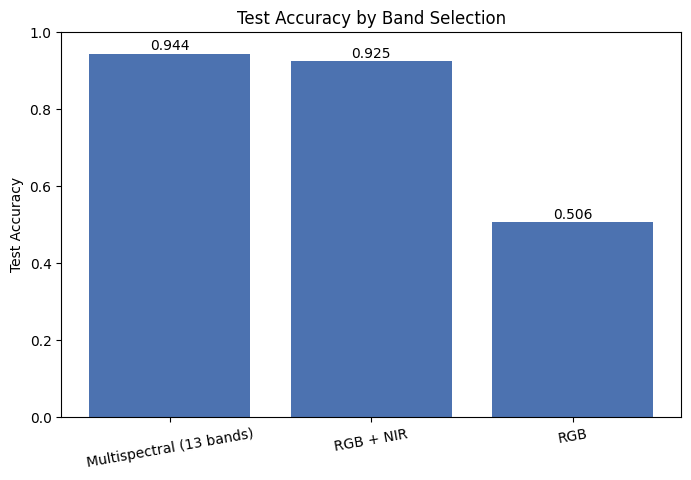

In [14]:
plt.figure(figsize=(8, 5))
bars = plt.bar(comparison_df["Experiment"], comparison_df["Test Accuracy"], color="#4C72B0")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy by Band Selection")
plt.ylim(0, 1)
for bar, val in zip(bars, comparison_df["Test Accuracy"]):
    plt.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.3f}", ha="center")
plt.xticks(rotation=10)
plt.show()

## 11. Macro F1 Comparison

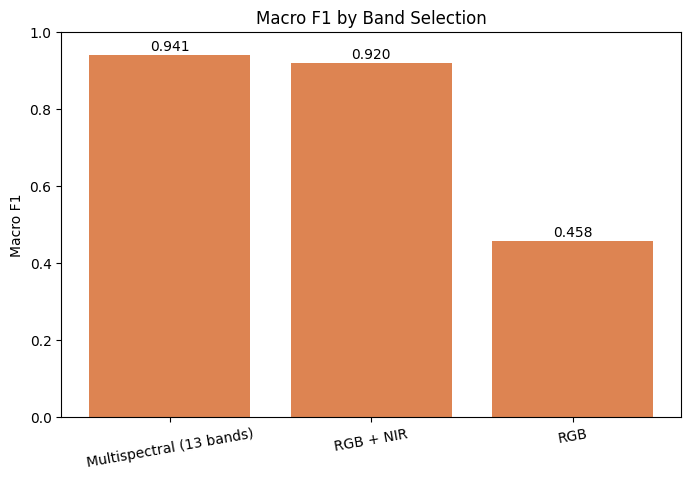

In [15]:
plt.figure(figsize=(8, 5))
bars = plt.bar(comparison_df["Experiment"], comparison_df["Macro F1"], color="#DD8452")
plt.ylabel("Macro F1")
plt.title("Macro F1 by Band Selection")
plt.ylim(0, 1)
for bar, val in zip(bars, comparison_df["Macro F1"]):
    plt.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.3f}", ha="center")
plt.xticks(rotation=10)
plt.show()

## 12. Confusion Matrices

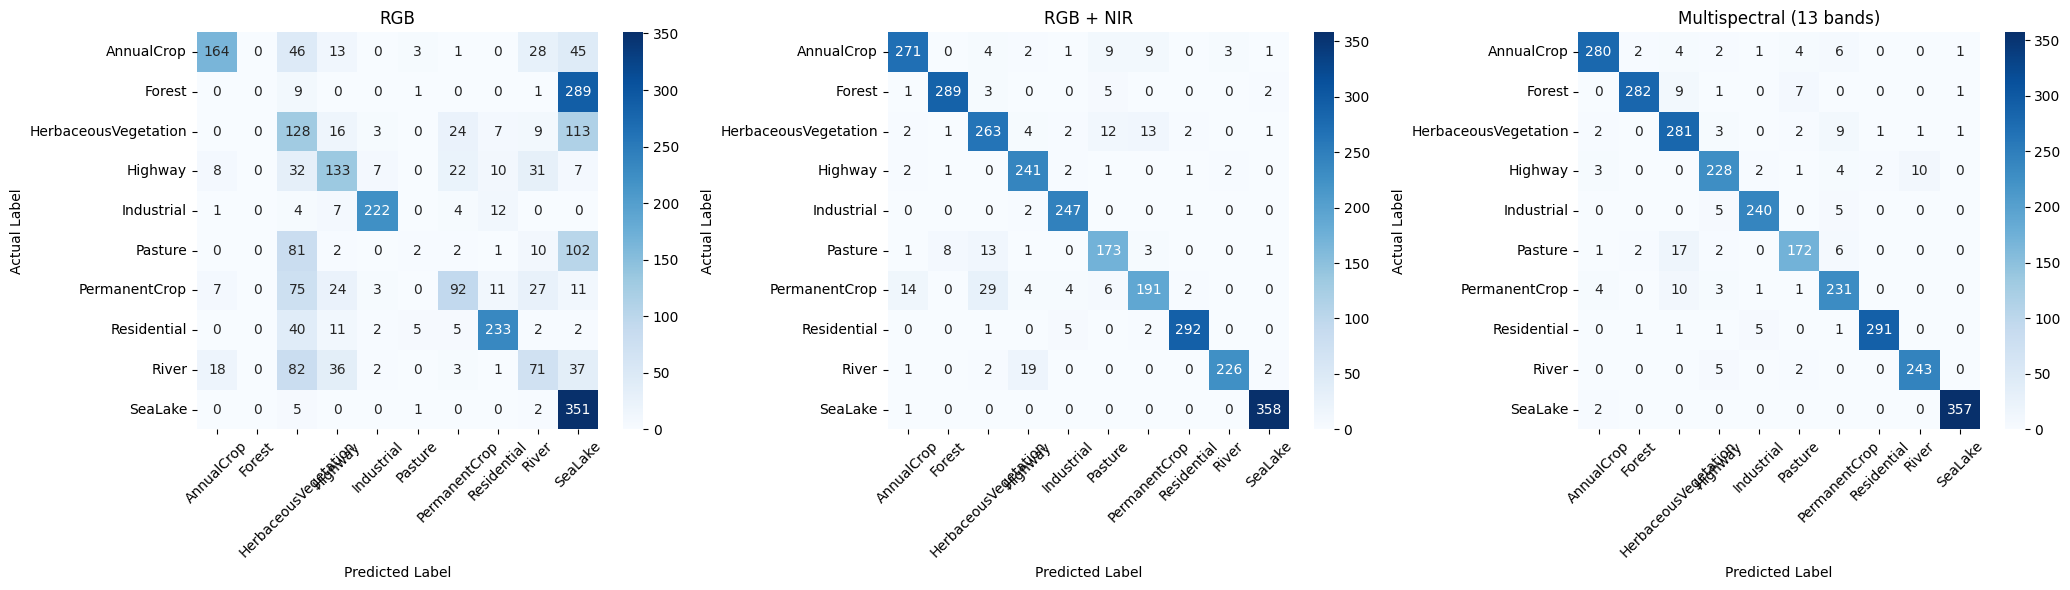

In [16]:
n_exp = len(results)
fig, axes = plt.subplots(1, n_exp, figsize=(7 * n_exp, 6))
if n_exp == 1:
    axes = [axes]

for ax, (name, r) in zip(axes, results.items()):
    sns.heatmap(
        r["confusion_matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

## 14. Analysis / Conclusion

Read `comparison_df` together with the confusion matrices above to fill this in once the three runs have finished:

- **RGB -> RGB+NIR:** does one extra band move test accuracy and macro F1 meaningfully, or is it within noise of the RGB baseline? Check whether the confusion pairs that NIR should help with (`Pasture`/`PermanentCrop`, `River`/`SeaLake`) actually shrink.
- **RGB+NIR -> Multispectral:** does going from 4 to 13 bands keep paying off, or do the returns flatten out? A frozen ImageNet backbone was never trained to interpret SWIR or red-edge statistics, so it's plausible the band adapter can't extract much more than it already got from NIR.
- **Cost vs. benefit:** cross-reference the accuracy gain against the training-time cost in Section 13. If the multispectral run costs noticeably more for only a marginal accuracy gain, `RGB + NIR` may be the more practical choice for a deployment that has to stay within a compute or latency budget.

### Save All Models and Results

Every trained model is saved, not just the best-scoring one — the run with the highest test accuracy here isn't necessarily the right choice for a resource-constrained deployment, so all three stay available for reuse.

In [18]:
for name, r in results.items():
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("+", "plus")
    filename = f"eurosat_bands_{safe_name}.keras"
    r["model"].save(filename)
    print("Saved:", filename)

comparison_df.to_csv("eurosat_band_selection_comparison.csv", index=False)
print("Saved comparison table: eurosat_band_selection_comparison.csv")

top_name = comparison_df.iloc[0]["Experiment"]
top_accuracy = comparison_df.iloc[0]["Test Accuracy"]
print(
    "\nThe band selection with the highest test accuracy in this experiment was "
    f"{top_name} ({top_accuracy * 100:.2f}%) — this reflects performance under this "
    "specific setup (frozen ConvNeXtTiny, this dataset split, these training settings), "
    "not a universal ranking of band combinations."
)

comparison_df

Saved: eurosat_bands_rgb.keras
Saved: eurosat_bands_rgb_plus_nir.keras
Saved: eurosat_bands_multispectral_13_bands.keras
Saved comparison table: eurosat_band_selection_comparison.csv

The band selection with the highest test accuracy in this experiment was Multispectral (13 bands) (94.42%) — this reflects performance under this specific setup (frozen ConvNeXtTiny, this dataset split, these training settings), not a universal ranking of band combinations.


,Experiment,Bands,Test Accuracy,Macro F1,Best Val Accuracy,Macro Precision,Macro Recall,Weighted F1,Test Loss,Training Time (s),Training Time (min)
0,Multispectral (13 bands),13,0.944183,0.940802,0.944012,0.941990,0.940243,0.944377,0.167537,628.809106,10.48
1,RGB + NIR,4,0.924610,0.919626,0.918463,0.921053,0.919888,0.924172,0.201812,615.771249,10.26
2,RGB,3,0.505980,0.457524,0.530531,0.493600,0.480972,0.467715,1.237936,354.332354,5.91
